# How IMSTE builds a 2D embedding

This tutorial starts by fitting IMSTE to a stratified MNIST sample, producing a 2D embedding from the original 784 pixel features. We then use that 2D embedding to make the repeated MST structure and attraction/repulsion updates easy to see.

The MST panels and epoch sequence below operate on the fitted 2D coordinates. This second, small optimization pass is a teaching visualization of the mechanics in 2D; the initial IMSTE fit builds its graph from the original input features.


In [46]:
%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from sklearn.preprocessing import StandardScaler

repo_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / 'notebooks' / 'src' / 'high_dim_mst_gallery.py').is_file()), None)
if repo_root is not None:
    sys.path.insert(0, str(repo_root / 'notebooks' / 'src'))
    sys.path.insert(0, str(repo_root))

from high_dim_mst_gallery import load_mnist_family_dataset
from imste import IteratedMinimumSpanningTreeEmbedder
from imste.mst import build_mst_edges
from imste._optimizer import optimize_embedding


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Choose how many images to use

Set `SAMPLES_PER_CLASS` to control the tutorial size. The default gives 300 images total, enough to show class structure while keeping the MST overlays readable. The loader caches the full MNIST download in the project data cache.


In [47]:
SAMPLES_PER_CLASS = 60  # change this value; MNIST has 10 classes
RANDOM_STATE = 42

X_all, y_all = load_mnist_family_dataset('MNIST')
rng = np.random.RandomState(RANDOM_STATE)
chosen = np.concatenate([
    rng.choice(np.flatnonzero(y_all == label), SAMPLES_PER_CLASS, replace=False)
    for label in np.unique(y_all)
])
rng.shuffle(chosen)
y = np.asarray(y_all[chosen], dtype=int)
X = StandardScaler().fit_transform(np.asarray(X_all[chosen], dtype=np.float32)).astype(np.float32)
print(f'{len(X):,} images · {X.shape[1]} pixel features · {len(np.unique(y))} classes')


600 images · 784 pixel features · 10 classes


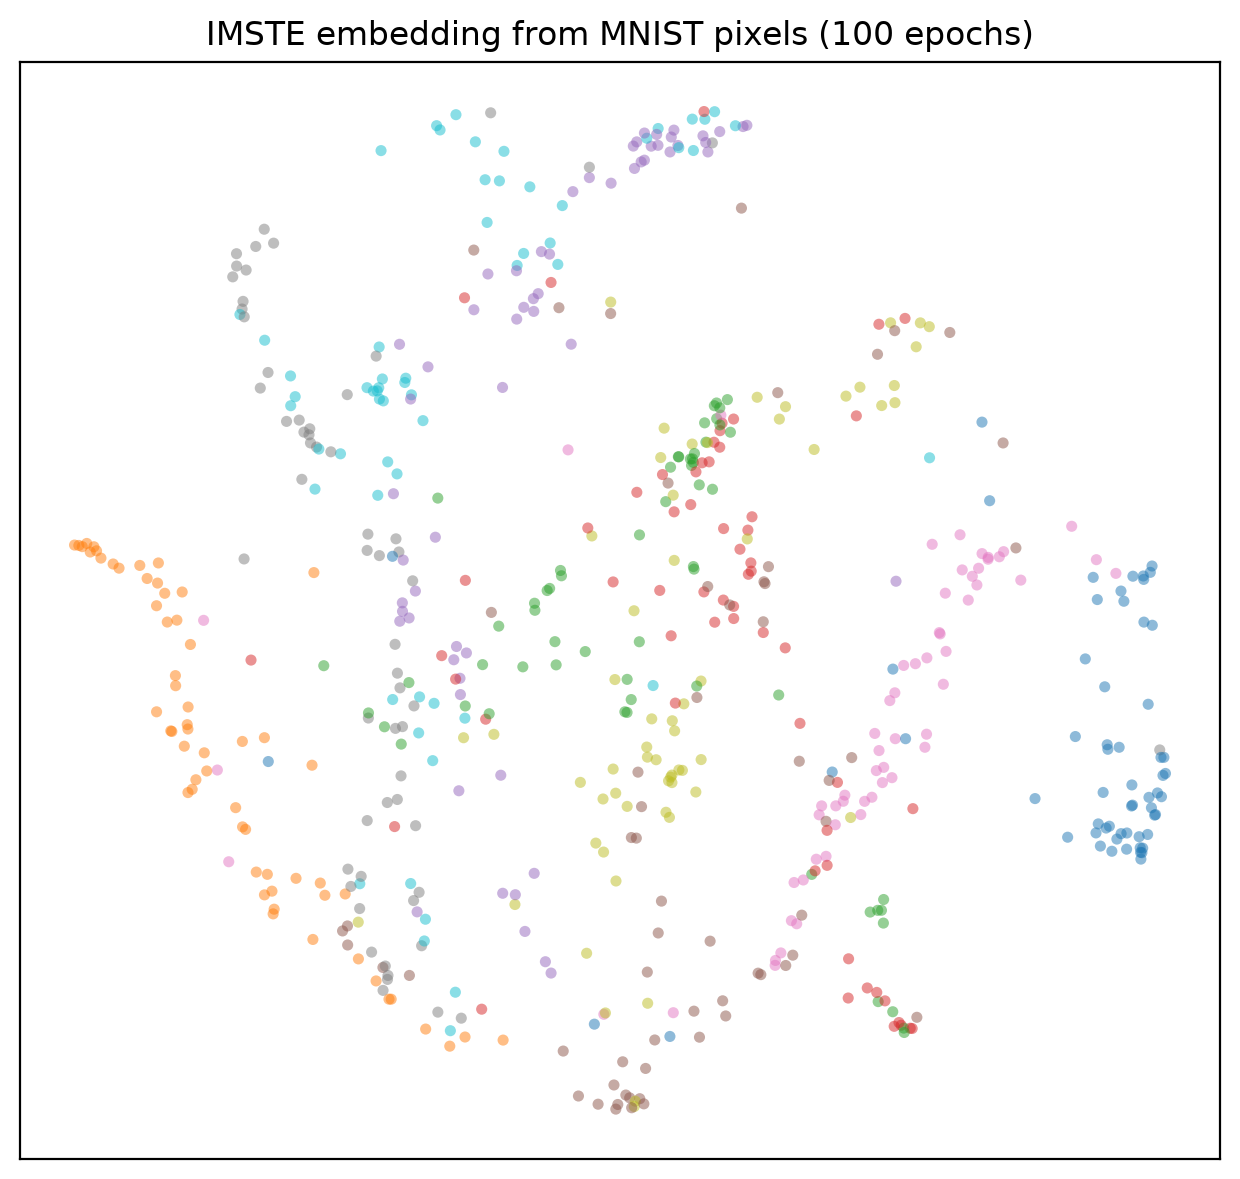

In [48]:
# Fit IMSTE on the original pixel vectors to get the 2D starting representation.
N_MSTS = 4
IMSTE_EPOCHS = 100
mapper = IteratedMinimumSpanningTreeEmbedder(
    n_components=2,
    n_msts=N_MSTS,
    n_epochs=IMSTE_EPOCHS,
    random_state=RANDOM_STATE,
    device='cpu',
    multilevel_init=False,
    gravity_strength=0.0,
    gravity_min_dist=0.0,
    mean_shift_iterations=0,
)
embedding_2d = mapper.fit_transform(X)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(embedding_2d[:, 0], embedding_2d[:, 1], c=y, cmap='tab10', s=16, alpha=0.5, linewidths=0)
ax.set_title(f'IMSTE embedding from MNIST pixels ({IMSTE_EPOCHS} epochs)')
ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal', adjustable='box')
fig.tight_layout()


## 2. Successive MSTs on the IMSTE embedding

The previous cell embeds the 784-dimensional pixel data with IMSTE. Here we build four ranked MSTs using distances between the resulting 2D coordinates. The first tree connects all points with the shortest total length and no cycles. Later trees prefer unused edges and reuse short edges only when needed; repeated edges have a higher rank and less attraction weight.

Each panel accumulates one more tree on the same IMSTE layout. The first tree is bold; each later tree is progressively thinner and lighter.


2,396 selected edges; 599 edges per tree


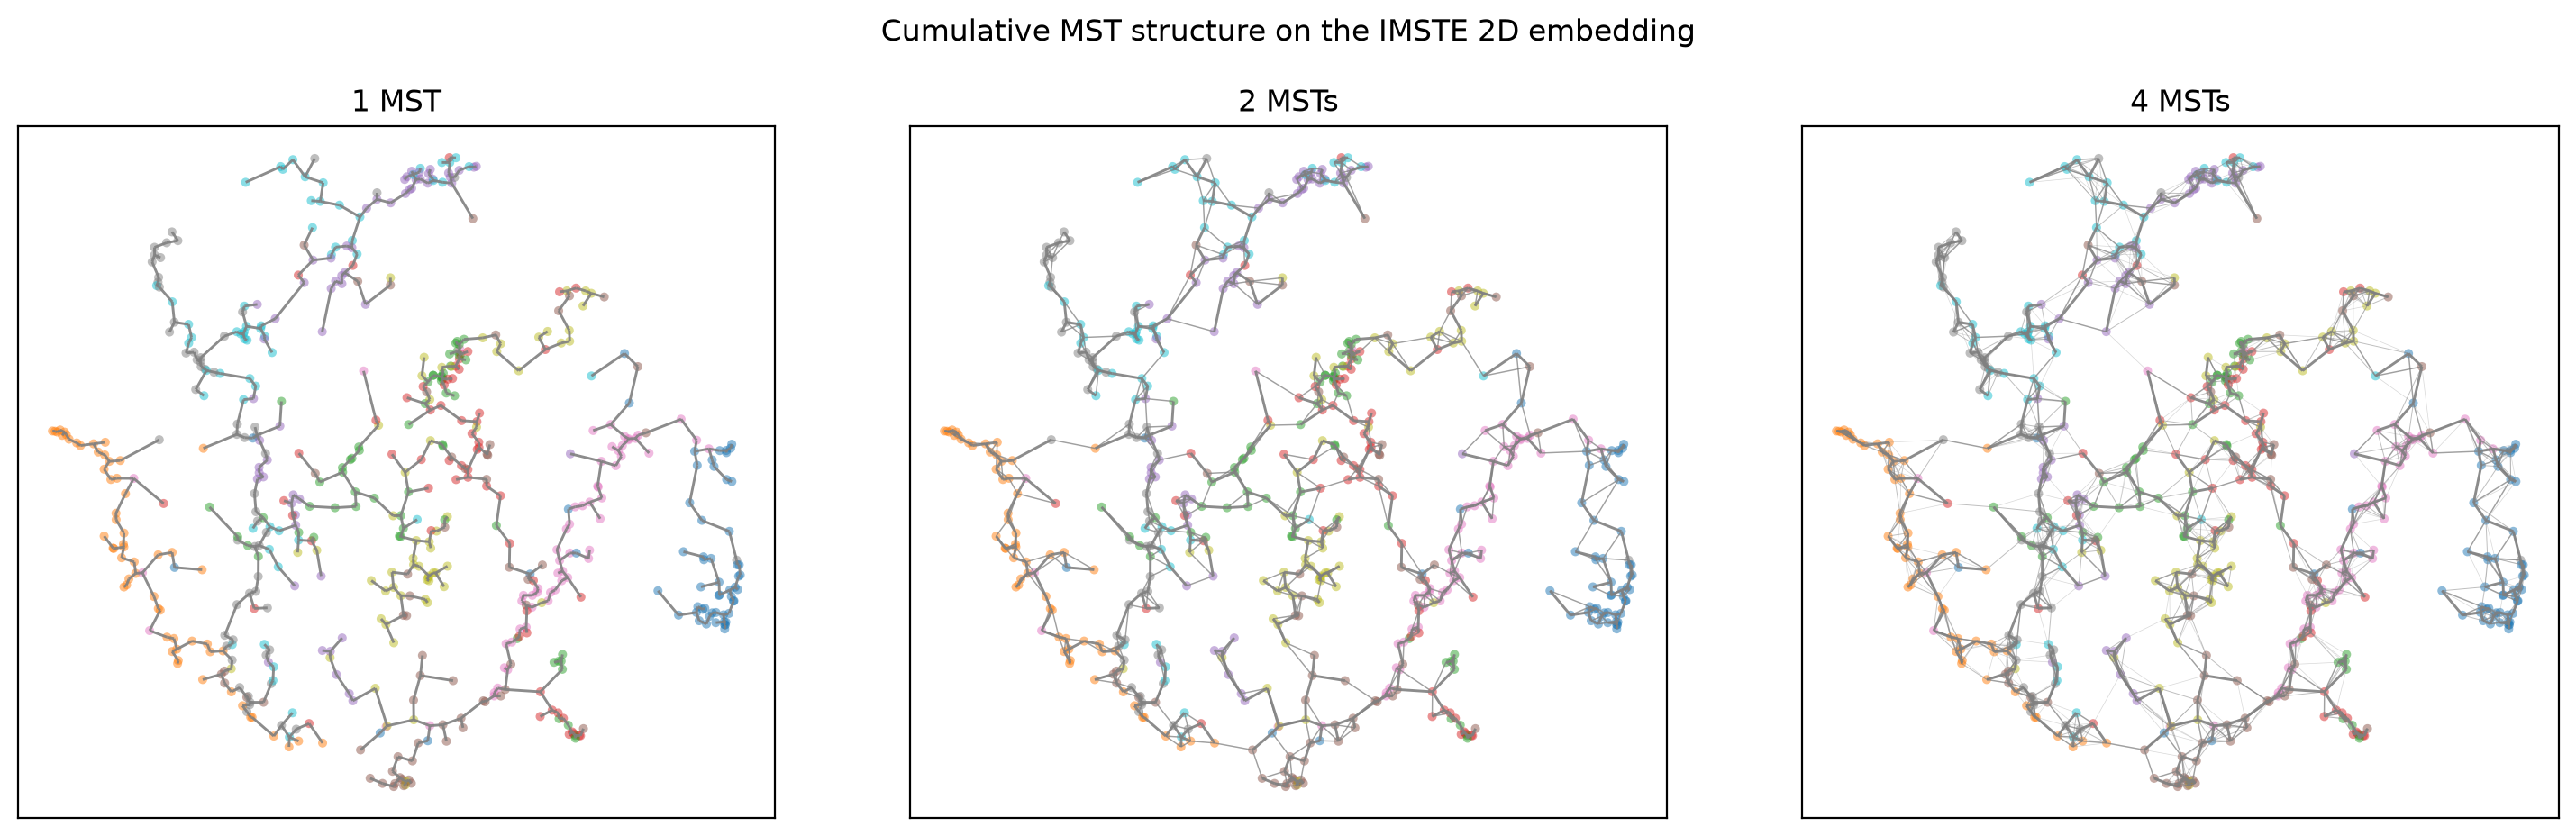

In [49]:
TREE_ALPHAS = (0.9, 0.75, 0.5, 0.3)
edges, ranks = build_mst_edges(
    embedding_2d, n_msts=N_MSTS, random_state=RANDOM_STATE, method='famst',
    neighbors=15, inter_component_edges=5, max_neighbors=None,
    representatives_per_component=10, neighbor_backend='auto', return_ranks=True,
)
print(f'{len(edges):,} selected edges; {len(embedding_2d) - 1:,} edges per tree')

SHOW_MST_COUNTS = (1, 2, 4)
fig, axes = plt.subplots(1, len(SHOW_MST_COUNTS), figsize=(15, 4.5), sharex=True, sharey=True)
for tree_count, ax in zip(SHOW_MST_COUNTS, axes):
    ax.scatter(embedding_2d[:, 0], embedding_2d[:, 1], c=y, cmap='tab10', s=13, alpha=0.5, linewidths=0)
    for tree_idx in range(tree_count):
        lo, hi = tree_idx * (len(embedding_2d) - 1), (tree_idx + 1) * (len(embedding_2d) - 1)
        tree_edges = edges[lo:hi]
        segments = np.stack([embedding_2d[tree_edges[:, 0]], embedding_2d[tree_edges[:, 1]]], axis=1)
        ax.add_collection(LineCollection(segments, colors='#808080',
                                         linewidths=1.05 / (tree_idx + 1),
                                         alpha=TREE_ALPHAS[tree_idx], zorder=1))
    ax.set_title(f'{tree_count} MST' + ('s' if tree_count > 1 else ''))
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal', adjustable='box')
fig.suptitle('Cumulative MST structure on the IMSTE 2D embedding', y=1.02)
fig.tight_layout()


## 3. Attraction and repulsion over epochs

To make the updates visible, we start from the fitted IMSTE 2D embedding, build the MST graph in that 2D space, and run a short second optimization pass on those coordinates. The three panels show the layout after epochs 1, 3, and 30.

Thin solid lines show MST attraction links. For a small set of anchor samples, arrows point toward tree neighbors (attraction) and away from representative non-tree samples (repulsion). These arrows illustrate pairwise directions; they are not a record of the exact negative pairs sampled in that epoch, and their lengths do not show gradient magnitude.


In [50]:
N_EPOCHS = 30
SHOW_EPOCHS = (1, 5, 30)
snapshots = {0: embedding_2d.copy()}

def capture_epoch(epoch, total):
    if epoch in SHOW_EPOCHS:
        snapshots[epoch] = Z.copy()

Z = embedding_2d.copy()
optimize_embedding(
    Z, edges, ranks, n_epochs=N_EPOCHS, learning_rate=0.05,
    negative_ratio=5, lambda_rep=0.5, epsilon=1e-4, margin=1.0,
    temperature=0.5, random_state=RANDOM_STATE, progress_callback=capture_epoch,
)
print('Captured epochs:', sorted(snapshots))


Captured epochs: [0, 1, 5, 30]


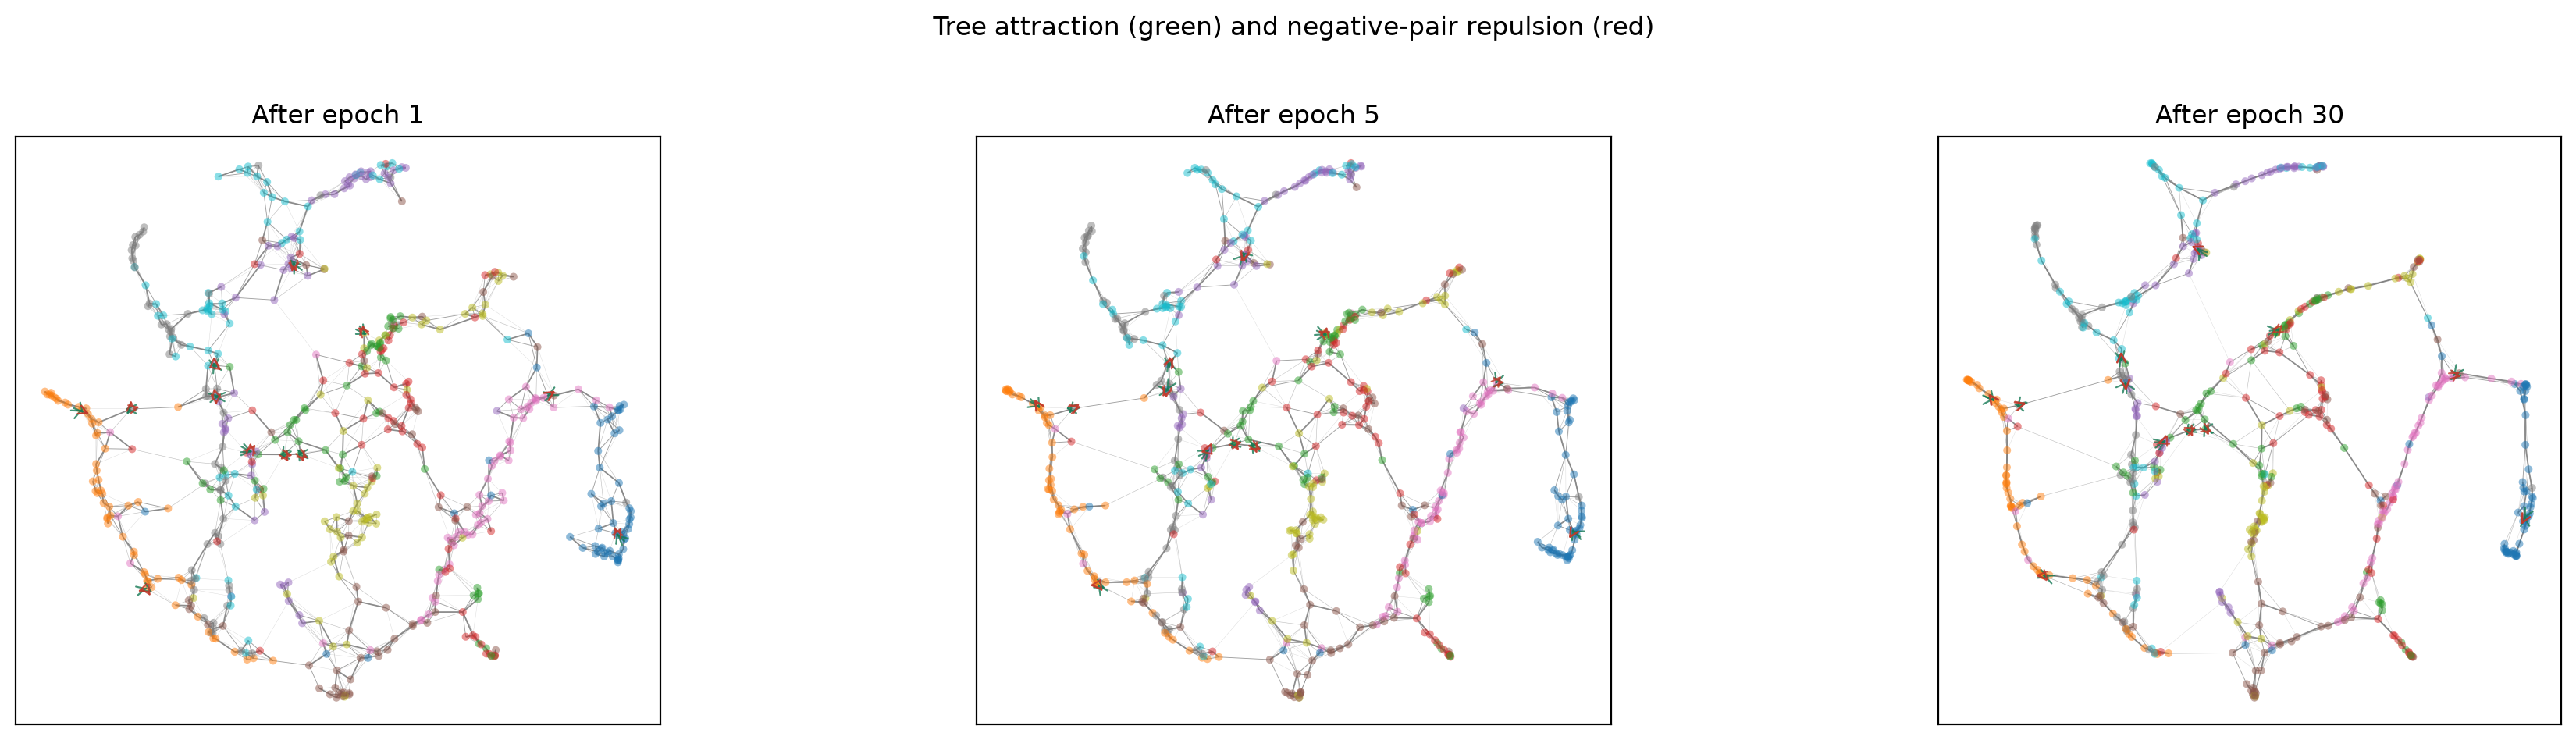

In [51]:
# Pick a few anchors spread across the sample and show local pairwise directions.
anchor_ids = np.linspace(0, len(embedding_2d) - 1, min(12, len(embedding_2d)), dtype=int)
tree_neighbors = [set() for _ in range(len(embedding_2d))]
for a, b in edges:
    tree_neighbors[a].add(b); tree_neighbors[b].add(a)

fig, axes = plt.subplots(1, len(SHOW_EPOCHS), figsize=(19, 4.6))
for ax, epoch in zip(axes, SHOW_EPOCHS):
    coords = snapshots[epoch]
    ax.scatter(coords[:, 0], coords[:, 1], c=y, cmap='tab10', s=13, alpha=0.5, linewidths=0, zorder=3)
    # Tree edges with inverse-rank styling: repeated edges attract less strongly.
    for rank in np.unique(ranks):
        selected = edges[ranks == rank]
        segs = np.stack([coords[selected[:, 0]], coords[selected[:, 1]]], axis=1)
        ax.add_collection(LineCollection(segs, colors='#808080',
                                         linewidths=0.65 / rank,
                                         alpha=TREE_ALPHAS[min(int(rank), len(TREE_ALPHAS)) - 1], zorder=1))
    for i in anchor_ids:
        # Attractive direction: toward a few incident tree neighbors.
        for j in list(tree_neighbors[i])[:2]:
            delta = coords[j] - coords[i]
            ax.annotate('', xy=coords[i] + 0.22 * delta, xytext=coords[i],
                        arrowprops=dict(arrowstyle='->', color='#167a55', lw=0.8, alpha=0.8), zorder=4)
        # Repulsive direction: away from the closest non-tree points.
        distances = np.sum((coords - coords[i]) ** 2, axis=1)
        distances[i] = np.inf
        candidate_order = np.argsort(distances)
        negatives = [j for j in candidate_order if j not in tree_neighbors[i]][:2]
        for j in negatives:
            delta = coords[i] - coords[j]
            norm = np.linalg.norm(delta) + 1e-8
            ax.annotate('', xy=coords[i] + 0.12 * delta / norm, xytext=coords[i],
                        arrowprops=dict(arrowstyle='->', color='#c0392b', lw=0.8, alpha=0.8), zorder=5)
    ax.set_title(f'After epoch {epoch}')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal', adjustable='box')
fig.suptitle('Tree attraction (green) and negative-pair repulsion (red)', y=1.02)
fig.tight_layout()


### Reading the panels

IMSTE first maps MNIST pixels into a 2D layout. We then build ranked MSTs on that layout and use them to illustrate the optimization forces: tree links attract, while sampled non-edges repel. Reused links receive less attraction weight, and the epoch panels show how the 2D points respond to the combined forces.

Change `SAMPLES_PER_CLASS`, `N_MSTS`, or `N_EPOCHS` and rerun the affected cells. The first IMSTE fit uses the original pixel features; the short follow-up pass is intentionally performed in 2D to keep the mechanism visible.
